# Prerequisite 05 · 机器学习基础：训练不是背 API

[上一章：数学](Prerequisite04_Math.ipynb) · [下一章：PyTorch](Prerequisite06_PyTorch.ipynb)

**目标：**理解模型、loss、优化、训练/验证/测试、过拟合和 baseline。RL 虽没有现成标签，但同样依赖这些训练原则。


## 1. 监督学习的最小闭环

给定输入 $x$ 和目标 $y$，模型产生 $\hat y=f_\theta(x)$，loss 衡量误差，梯度下降更新参数：

$$\theta\leftarrow\theta-\alpha\nabla_\theta L(\theta)$$

学习率 $\alpha$ 太小进展慢，太大会震荡或发散。RL 中 target 来自 reward 和 bootstrap，而不是人工标签，但优化器看到的仍是 loss。


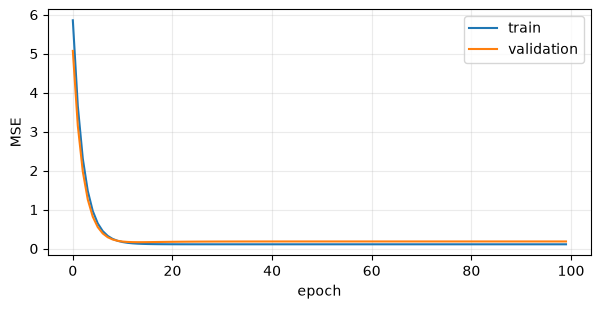

w/b: 2.542 -0.744 validation MSE: 0.183


In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(5)
x = rng.uniform(-2, 2, 160)
y = 2.5*x - .7 + rng.normal(0, .35, len(x))
indices = rng.permutation(len(x))
train_idx, val_idx = indices[:120], indices[120:]
w, b, lr = 0.0, 0.0, .08
train_loss, val_loss = [], []
for _ in range(100):
    error = w*x[train_idx] + b - y[train_idx]
    w -= lr * 2*np.mean(error*x[train_idx])
    b -= lr * 2*np.mean(error)
    train_loss.append(np.mean((w*x[train_idx]+b-y[train_idx])**2))
    val_loss.append(np.mean((w*x[val_idx]+b-y[val_idx])**2))

plt.figure(figsize=(7, 3.2)); plt.plot(train_loss, label="train"); plt.plot(val_loss, label="validation")
plt.xlabel("epoch"); plt.ylabel("MSE"); plt.grid(alpha=.25); plt.legend(); plt.show(); plt.close()
print("w/b:", round(w, 3), round(b, 3), "validation MSE:", round(val_loss[-1], 3))


## 2. 为什么要分 train / validation / test

- **train：**更新参数。
- **validation：**选择模型和超参数。
- **test：**所有决定完成后，只用于一次最终评估。

在 test 上反复调参，相当于把 test 变成 validation。股票、文本世界和网页任务尤其容易因时间或相似样本泄漏而得到虚高结果。


## 3. 过拟合、归一化和 baseline

- 训练 loss 继续下降、validation loss 上升，是典型过拟合信号。
- 归一化统计量只能从训练数据估计，再应用到 validation/test。
- 更复杂模型必须和随机、规则或简单线性 baseline 比较。
- 公平比较要固定数据、预算、指标与随机种子集合。

RL 的训练分布会随策略变化，因此比监督学习更难；这些原则不是可以跳过，反而更重要。


In [2]:
# 同一个错误尺度下，比较三个学习率的梯度下降轨迹。
def optimize(lr, steps=25):
    value, history = 4.0, []
    for _ in range(steps):
        value -= lr * 2*value  # d(value^2)/dvalue = 2*value
        history.append(value**2)
    return history

for lr in (.02, .2, 1.1):
    history = optimize(lr)
    print(f"lr={lr}: first={history[0]:.3f}, last={history[-1]:.3f}")


lr=0.02: first=14.746, last=2.078
lr=0.2: first=5.760, last=0.000
lr=1.1: first=23.040, last=145607.010


## 练习与过关标准

**练习：**解释为什么不能先对全部数据做标准化，再切分训练/测试；设计一个只比较学习率的公平实验。

**过关：**能解释 loss 与任务指标的区别；能正确划分数据；能识别过拟合和泄漏；知道一次只改变一个因素。

**选读：**[scikit-learn Getting Started](https://scikit-learn.org/stable/getting_started.html) 用于理解 fit/predict、预处理与模型评估；[Dive into Deep Learning 的线性模型部分](https://d2l.ai/chapter_linear-classification/)用于补充回归、分类和训练过程。
